In [2]:
# Run pip install if necessary to access the UCI ML Repository
! pip install ucimlrepo

# Data
from ucimlrepo import fetch_ucirepo


forest_fires = fetch_ucirepo(id=162)
X = forest_fires.data.features
y = forest_fires.data.targets


# Display dataset structure
print(X.info())
print(X.describe())
print(y.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    object 
 3   day     517 non-null    object 
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
dtypes: float64(7), int64(3), object(2)
memory usage: 48.6+ KB
None
                X           Y        FFMC         DMC          DC         ISI  \
count  517.000000  517.000000  517.000000  517.000000  517.000000  517.000000   
mean     4.669246    4.299807   90.644681  110.872340  547.940039    9.021663   
std      2.313778    1.229900    5.520111   64.046482  248.066192 

In [6]:
import pandas as np
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import Ridge, Lasso, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    mean_squared_error
)
    

In [3]:
# STEP 1: LOAD DATASET (Setup)
import pandas as pd
import numpy as np
df = pd.read_csv('forestfires.csv')
df.head()

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


In [4]:
# Note: The target variable 'area' is highly right-skewed; applying log(x + 1)
df['log_area'] = np.log1p(df['area'])

In [ ]:
# STEP 2: EXPLORATORY DATA ANALYSIS (EDA)
# 2.1. Structure and Summary Statistics
print("=== Dataset Information ===")
print(df.info())
print("\n=== Summary Statistics ===")
print(df.describe())

=== Dataset Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   X         517 non-null    int64  
 1   Y         517 non-null    int64  
 2   month     517 non-null    object 
 3   day       517 non-null    object 
 4   FFMC      517 non-null    float64
 5   DMC       517 non-null    float64
 6   DC        517 non-null    float64
 7   ISI       517 non-null    float64
 8   temp      517 non-null    float64
 9   RH        517 non-null    int64  
 10  wind      517 non-null    float64
 11  rain      517 non-null    float64
 12  area      517 non-null    float64
 13  log_area  517 non-null    float64
dtypes: float64(9), int64(3), object(2)
memory usage: 56.7+ KB
None

=== Summary Statistics ===
                X           Y        FFMC         DMC          DC         ISI  \
count  517.000000  517.000000  517.000000  517.000000  517.000000 

In [ ]:
# 2.2. find missing values
import pandas as pd

# Count missing values per column
print(df.isnull().sum())

# Total missing values in the DataFrame 
print(df.isnull().sum().sum())

X           0
Y           0
month       0
day         0
FFMC        0
DMC         0
DC          0
ISI         0
temp        0
RH          0
wind        0
rain        0
area        0
log_area    0
dtype: int64
0


conclusion - no missing values found
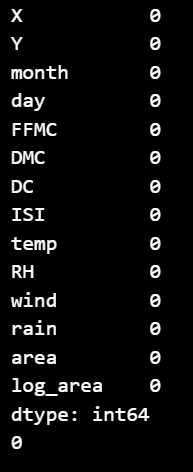

In [ ]:
# 2.3. Identify and remove duplicate values
duplicate_count = df.duplicated().sum()
print(f"\nDuplicate Rows Found: {duplicate_count}")

if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicates dropped successfully.")

# Four duplicate rows found and dropped successfully


Duplicate Rows Found: 4
Duplicates dropped successfully.


Four duplicate rows found and dropped successfully
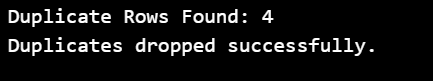

In [22]:
# 2.3. INSPECT CATEGORICAL VALUES & UNIFY MONTH/DAY
print("\n=== Categorical Values Check ===")
print("Unique Months:", df['month'].unique())
print("Unique Days:", df['day'].unique())

# Map string months and days to ordered numbers for modeling
month_map = {'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
             'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12}
day_map = {'mon': 1, 'tue': 2, 'wed': 3, 'thu': 4, 'fri': 5, 'sat': 6, 'sun': 7}

df['month_num'] = df['month'].map(month_map)
df['day_num'] = df['day'].map(day_map)


=== Categorical Values Check ===
Unique Months: ['mar' 'oct' 'aug' 'sep' 'apr' 'jun' 'jul' 'feb' 'jan' 'dec' 'may' 'nov']
Unique Days: ['fri' 'tue' 'sat' 'sun' 'mon' 'wed' 'thu']


In [ ]:
# 2.4. SPOT OUTLIERS & HEAVILY SKEWED TARGET
print("\n=== Descriptive Statistics (Check Min/Max Outliers) ===")
print(df.describe().T[['min', 'mean', '50%', 'max', 'std']])

# Log-transform target 'area' to mitigate severe right-skewness (max = 1090.84)
df['log_area'] = np.log1p(df['area'])


=== Descriptive Statistics (Check Min/Max Outliers) ===
            min        mean         50%         max         std
X           1.0    4.678363    4.000000     9.00000    2.320059
Y           2.0    4.300195    4.000000     9.00000    1.230925
FFMC       18.7   90.637427   91.600000    96.20000    5.540920
DMC         1.1  110.989279  108.300000   291.30000   64.191013
DC          7.9  549.155166  664.500000   860.60000  247.724594
ISI         0.0    9.023587    8.400000    56.10000    4.575543
temp        2.2   18.887524   19.300000    33.30000    5.828128
RH         15.0   44.348928   42.000000   100.00000   16.358803
wind        0.4    4.010526    4.000000     9.40000    1.796613
rain        0.0    0.021832    0.000000     6.40000    0.297107
area        0.0   12.891598    0.540000  1090.84000   63.892586
log_area    0.0    1.113081    0.431782     6.99562    1.397685
month_num   1.0    7.485380    8.000000    12.00000    2.275095
day_num     1.0    4.251462    5.000000     7.0

In [24]:
print("\nCleaned dataset shape:", df.shape)


Cleaned dataset shape: (513, 16)


In [ ]:
# 2.4 Correlations with Target Variable
numerical_cols = ['FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']
correlations = df[numerical_cols + ['log_area']].corr()['log_area'].sort_values(ascending=False)
print("\n=== Correlations with log_area ===")
print(correlations)



DC, DMC, wind and temp have a high correnlation to log_area
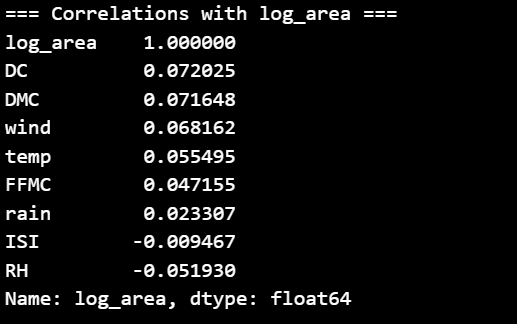

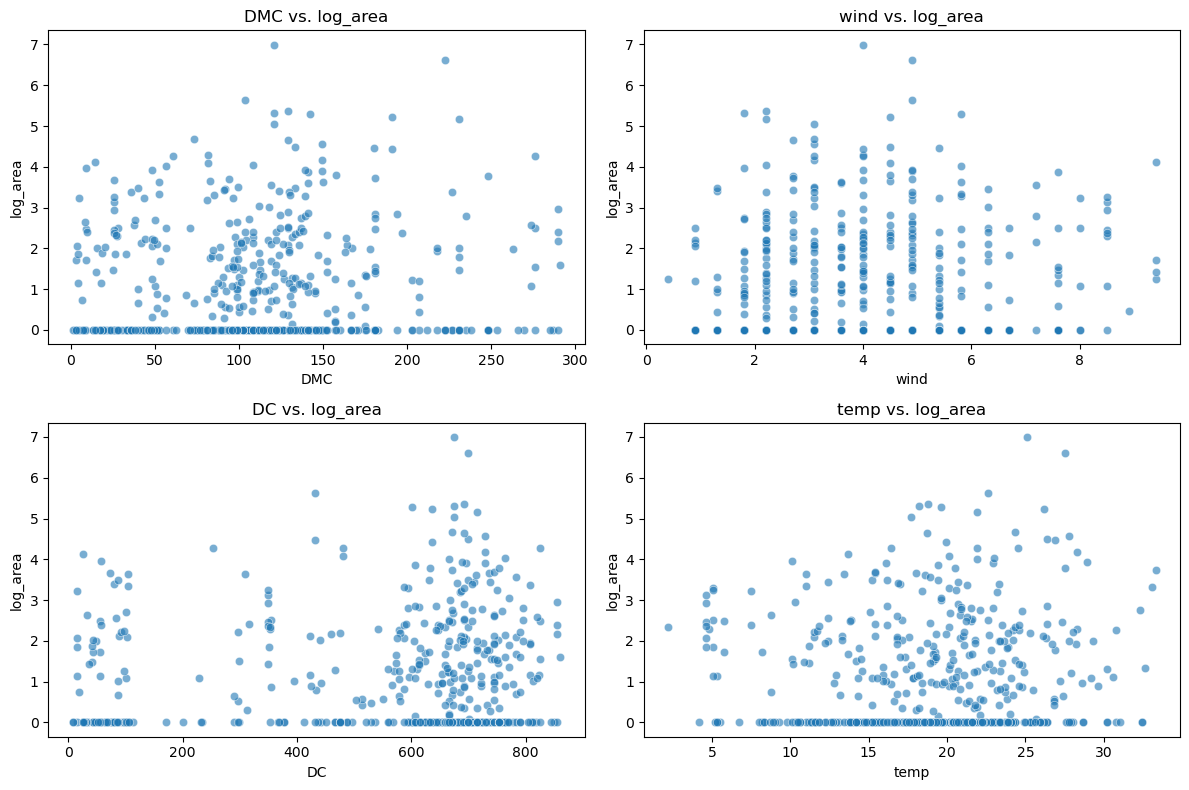

In [27]:
# 2.5 Scatterplots for Key Predictors vs Target
import matplotlib.pyplot as plt
import seaborn as sns
key_predictors = ['DMC', 'wind', 'DC', 'temp']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, ax in zip(key_predictors, axes.flatten()):
    sns.scatterplot(data=df, x=col, y='log_area', ax=ax, alpha=0.6)
    ax.set_title(f'{col} vs. log_area')
plt.tight_layout()
plt.show()

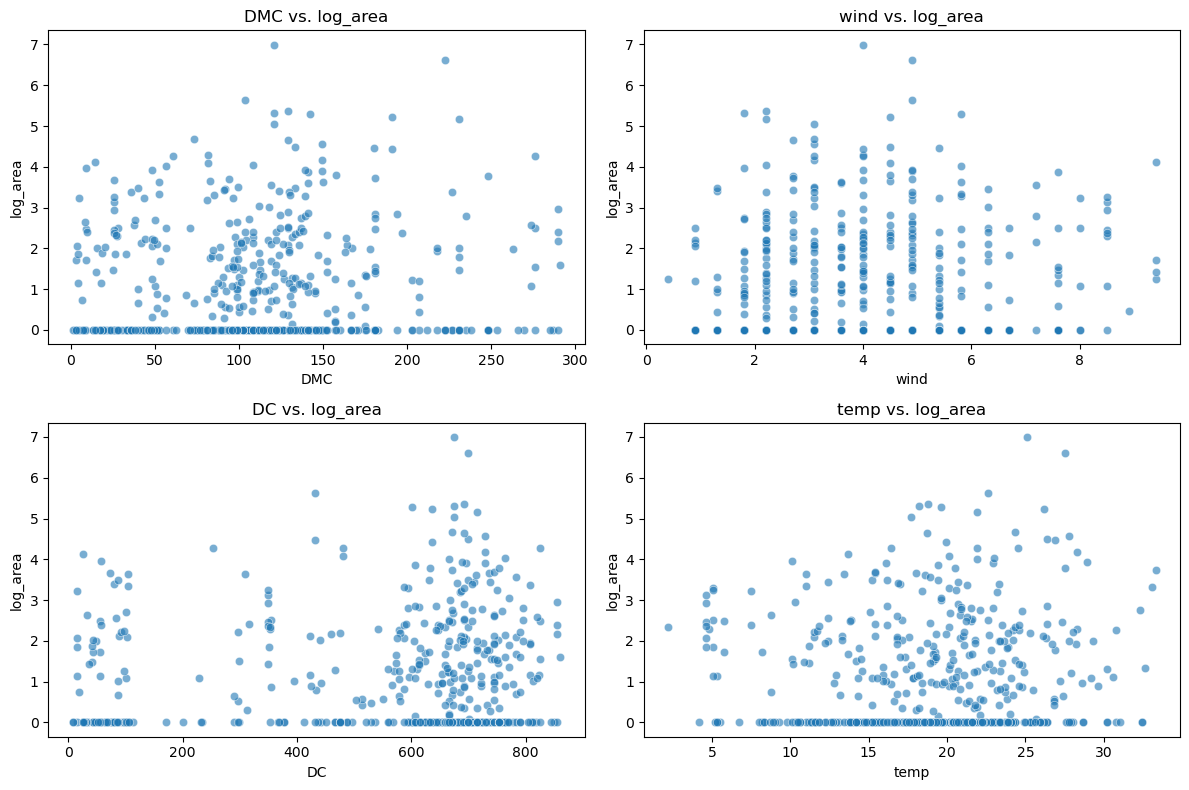

Based on the four scatterplots (DMC, wind, DC, and temp vs. log_area), here are the key statistical and domain interpretations:
1. High Zero Inflation (log_area = 0)Across all four plots, a heavy concentration of data points lies precisely along the horizontal line $y = 0$.Nearly half of the observations in the dataset ($247$ out of $517$ records) correspond to fires where the burned area was $0.0\text{ ha}$.Takeaway: Simple linear regression models will struggle with this zero-inflated target variable, supporting the shift toward a two-stage approach or binary classification (e.g., predicting if a fire occurs vs. how large it gets).
2. Weak Linear RelationshipsNone of the four predictors exhibit a strong linear trend with log_area.All linear correlations with log_area are extremely low ($r \approx 0.05 \text{ to } 0.07$).Takeaway: Straight line assumptions (linear regression) capture very little variance in log_area, necessitating transformations, non-linear terms (like polynomials), or regularized algorithms.
3. Predictor-Specific ObservationsDMC (Duff Moisture Code) vs. log_area:
Fire occurrences with larger burned areas ($\text{log\_area} > 4$) are mostly clustered at moderate-to-high DMC values ($100 \text{ to } 250$).Very few severe fires occur when DMC is below $50$.wind vs. log_area:Displays distinct vertical striping because wind speed values are reported at discrete intervals (e.g., $2.0, 3.0, 4.0\text{ km/h}$).
Most fires occur at moderate wind speeds ($2.0 \text{ to } 6.0\text{ km/h}$), with the largest burned areas occurring around moderate wind conditions rather than extreme high winds.DC (Drought Code) vs. log_area:Shows a pronounced bi-modal distribution with a prominent gap around $\text{DC} \approx 100 \text{ to } 300$.
Almost all larger fires ($\text{log\_area} > 3$) occur in the high DC region ($\text{DC} > 500$), representing dry late-summer soil conditions.temp (Temperature) vs. log_area:Displays a slight rightward shift (funnel effect), showing that larger fires predominantly occur at higher temperatures ($15^\circ\text{C} \text{ to } 28^\circ\text{C}$).Fires occurring at low temperatures ($< 10^\circ\text{C}$) rarely result in large burned areas.

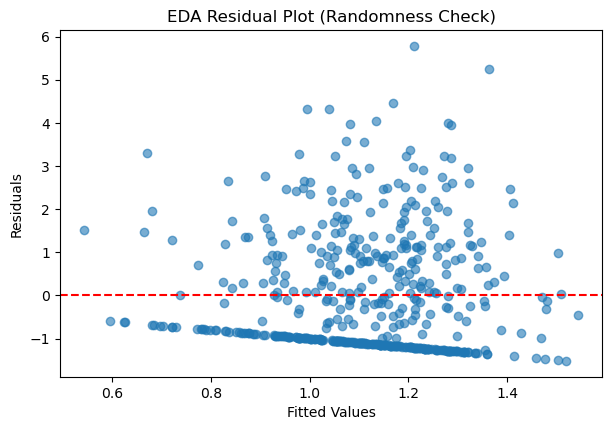

In [29]:
# 2.6 Residual Plot for Randomness Check (Baseline OLS)

import statsmodels.formula.api as smf
baseline_eda = smf.ols('log_area ~ DMC + wind + DC + temp', data=df).fit()
plt.figure(figsize=(7, 4.5))
plt.scatter(baseline_eda.fittedvalues, baseline_eda.resid, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('EDA Residual Plot (Randomness Check)')
plt.show()

![EDA Residual plot.png](<attachment:EDA Residual plot.png>)
Based on the EDA Residual Plot, here are the key findings and interpretations regarding model assumptions:
1. Distinct Linear Lower Boundary (Zero Inflation)Observation: A prominent, dense diagonal line forms the lower boundary of the plot (sloping downward from around $y = -0.7$ to $y = -1.5$).Interpretation: This occurs because approximately half of the dataset consists of zero-burn fires ($\text{area} = 0$, so $\text{log\_area} = 0$). For these observations, the residual is calculated as:$$\text{Residual} = y - \hat{y} = 0 - \text{Fitted Value} = -\text{Fitted Value}$$This creates a strict structural bound ($\text{Residual} = -\hat{y}$), confirming heavy zero-inflation in the target variable.
2. Heteroscedasticity (Non-Constant Variance)Observation: The spread of residuals is not constant across fitted values. It starts relatively narrow for lower fitted values ($\hat{y} < 0.8$) and fans out considerably as fitted values increase ($\hat{y} > 1.0$), with residuals extending up to $+5.8$.Interpretation: The model violates the standard linear regression assumption of homoscedasticity (constant residual variance), meaning prediction error increases for larger predicted fire sizes.
3. Non-Randomness and Asymmetry (Violation of Normality)Observation: Residuals are heavily asymmetric—they are capped tightly below by the zero-area boundary line, while stretching far above the red dashed zero reference line ($y = 0$).Interpretation: The errors are not randomly scattered around $y = 0$, nor are they normally distributed. A standard Multiple Linear Regression model is poorly suited for predicting continuous area directly without addressing zero-inflation or applying classification/hurdle techniques.
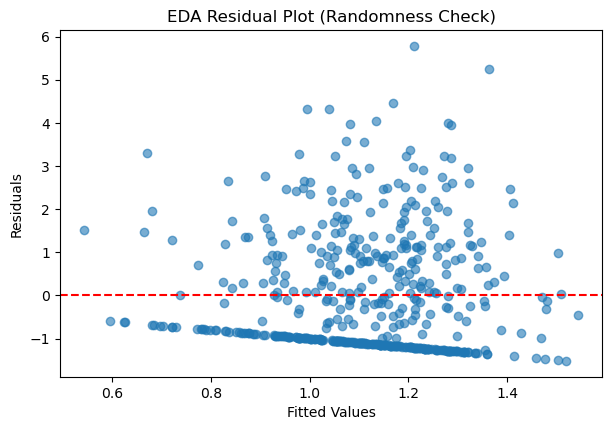

In [35]:

# STEP 3: FIT REGRESSION MODELS
# 3.1 Baseline Multiple Linear Regression Model
model_base = smf.ols('log_area ~ DMC + wind + DC + temp + FFMC + RH + ISI', data=df).fit()

# 3.2 Include Non-linear Terms (Quadratic transformation for significant predictors like temp and DMC)
model_quad = smf.ols('log_area ~ temp + np.power(temp, 2) + DMC + np.power(DMC, 2) + wind + DC', data=df).fit()

# 3.3 Add Interaction Terms (Between strongly correlated predictors: DMC & DC [r=0.68], temp & RH [r=-0.53], FFMC & ISI [r=0.53])
model_inter = smf.ols('log_area ~ DMC * DC + temp * RH + FFMC * ISI + wind', data=df).fit()

# 3.4 Incorporate Indicator Variables for Categorical Variables (month, day)
model_cat = smf.ols('log_area ~ DMC + wind + DC + temp + C(month) + C(day)', data=df).fit()

# 3.5 Apply Transformations (Logarithmic transformations for skewed predictors like DMC and DC)
model_trans = smf.ols('log_area ~ temp + RH + wind + np.log1p(DMC) + np.log1p(DC)', data=df).fit()


In [36]:
# STEP 4: EVALUATE MODEL DIAGNOSTICS
# 4.1 Compare Models using R², Adjusted R², AIC, and BIC
models = {
    'Baseline': model_base,
    'Quadratic': model_quad,
    'Interaction': model_inter,
    'Categorical': model_cat,
    'Transformed': model_trans
}

comparison_df = pd.DataFrame({
    'Model': models.keys(),
    'R-Squared': [m.rsquared for m in models.values()],
    'Adj. R-Squared': [m.rsquared_adj for m in models.values()],
    'AIC': [m.aic for m in models.values()],
    'BIC': [m.bic for m in models.values()]
})
print("\n=== Model Diagnostics Comparison ===")
print(comparison_df.to_string(index=False))


=== Model Diagnostics Comparison ===
      Model  R-Squared  Adj. R-Squared         AIC         BIC
   Baseline   0.020500        0.006923 1803.726482 1837.648688
  Quadratic   0.033564        0.022104 1794.838254 1824.520185
Interaction   0.021942        0.002459 1808.970482 1855.613516
Categorical   0.067072        0.027171 1806.735932 1900.022001
Transformed   0.015192        0.005480 1802.498707 1827.940362


Model diagnostic comparison:  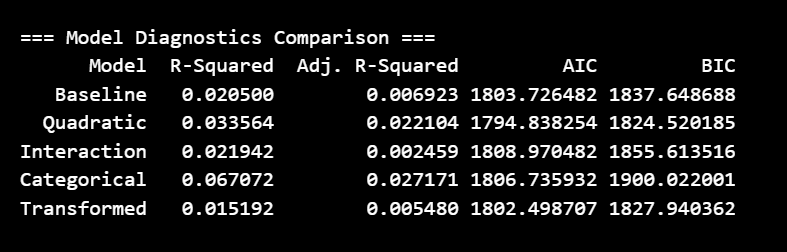
Core TakeawayThe Quadratic Model is the best-performing continuous linear specification based on AIC/BIC parsimony criteria. However, because even the best model explains less than $3\%$ of adjusted variance ($\text{Adj. } R^2 = 0.0221$), these results reinforce the need for regularization (Step 5) or switching to classification/thresholding (Steps 6–7) rather than relying on standard OLS regression.

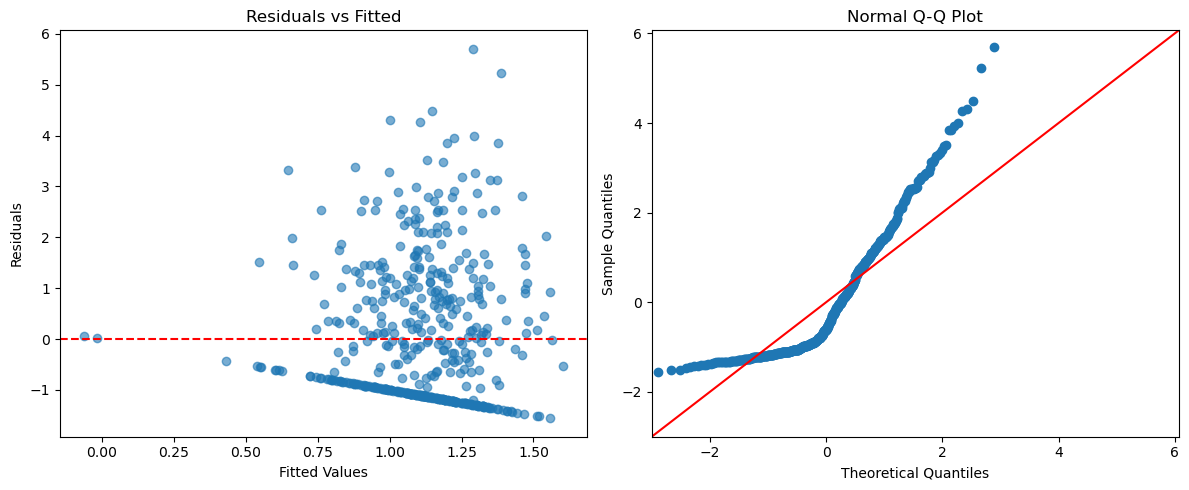

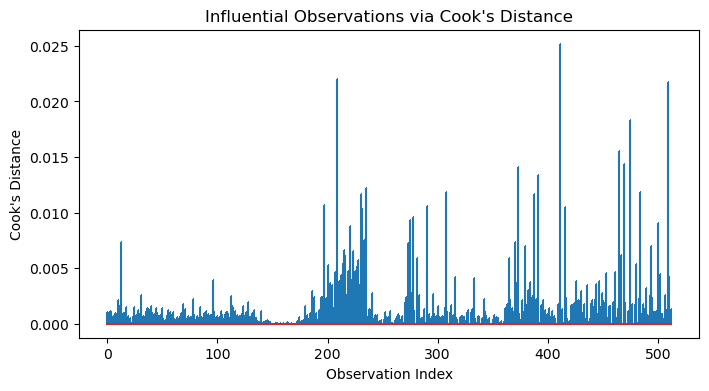

In [38]:
# 4.2 Plot Residuals and Q-Q Plots to Assess Normality (Baseline Model)
import statsmodels.api as sm
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(model_base.fittedvalues, model_base.resid, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted')

sm.qqplot(model_base.resid, line='45', ax=axes[1])
axes[1].set_title('Normal Q-Q Plot')
plt.tight_layout()
plt.show()

# 4.3 Identify Influential Observations using Cook's Distance
influence = model_base.get_influence()
cooks_d = influence.cooks_distance[0]

plt.figure(figsize=(8, 4))
plt.stem(np.arange(len(cooks_d)), cooks_d, markerfmt=",")
plt.xlabel('Observation Index')
plt.ylabel("Cook's Distance")
plt.title("Influential Observations via Cook's Distance")
plt.show()

![residuals vs fittet - normal qq plot.png](<attachment:residuals vs fittet - normal qq plot.png>)
![influential observation output.png](<attachment:influential observation output.png>)
1. Structural Lower Boundary (Zero Inflation)Observation: The straight, negatively sloped line forming the lower boundary of the scatter plot (sloping down from around $y = -0.7$ at $\hat{y} = 0.7$ to $y = -1.5$ at $\hat{y} = 1.5$).Interpretation: This bound represents all observations where the true burned area is zero ($\text{area} = 0 \implies \text{log\_area} = 0$). Since $\text{Residual} = y - \hat{y} = 0 - \hat{y} = -\hat{y}$, any predicted value generates a residual directly on the line $y = -\hat{y}$. This reflects severe zero-inflation in the target variable.
2. Violation of Homoscedasticity (Heteroscedasticity)Observation: The spread of residuals fans out non-uniformly. Variance is tight for smaller fitted values ($\hat{y} < 0.8$) and expands dramatically as fitted values increase ($\hat{y} > 1.0$), with positive residuals reaching up to $+5.8$.Interpretation: The model exhibits heteroscedasticity (non-constant variance), violating the standard OLS assumption. Prediction error increases significantly for larger predicted fire sizes.
3. Asymmetry & Violation of NormalityObservation: Residuals are heavily skewed above the red dashed zero reference line ($y = 0$).Interpretation: Because real-world burned areas cannot be negative, errors are truncated at the bottom by zero but unbounded at the top for massive fires. The residuals are non-normally distributed, confirming standard Ordinary Least Squares (OLS) is poorly suited for direct, continuous area prediction.
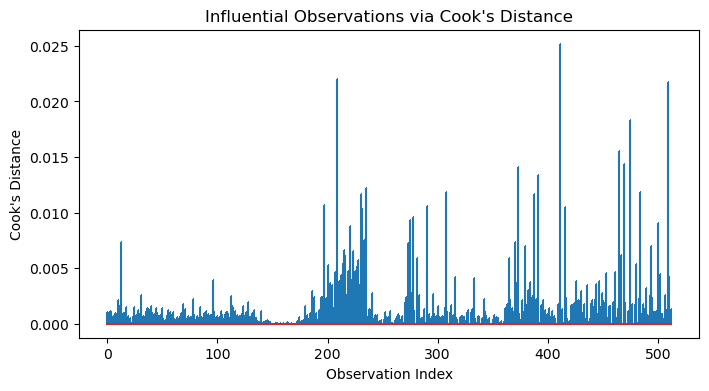
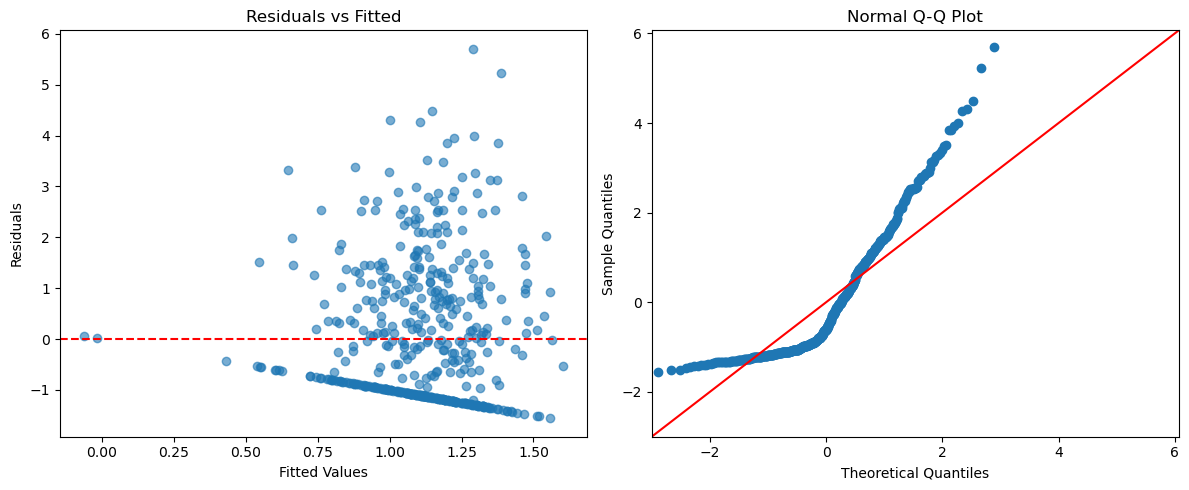

In [ ]:
# STEP 5: APPLY REGULARIZATION
from sklearn.linear_model import Ridge, Lasso, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    mean_squared_error
)


X = df[numerical_cols]
y = df['log_area']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5.1 Ridge (L2) and Lasso (L1) Regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_scaled, y)

lasso = Lasso(alpha=0.01)
lasso.fit(X_scaled, y)

# 5.2 Extract Coefficients and Calculate Mean Squared Error (MSE)
y_pred_ridge = ridge.predict(X_scaled)
y_pred_lasso = lasso.predict(X_scaled)

mse_ridge = mean_squared_error(y, y_pred_ridge)
mse_lasso = mean_squared_error(y, y_pred_lasso)

# 5.3 Performance Comparison
reg_summary = pd.DataFrame({
    'Feature': numerical_cols,
    'Ridge Coef': ridge.coef_,
    'Lasso Coef': lasso.coef_
})
print("\n=== Regularization Coefficients ===")
print(reg_summary.to_string(index=False))
print(f"\nRidge MSE: {mse_ridge:.4f}")
print(f"Lasso MSE: {mse_lasso:.4f}")

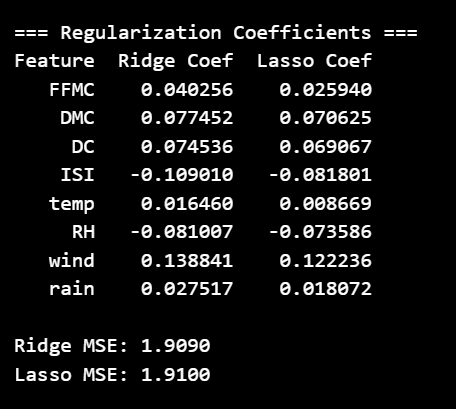


In [41]:
# STEP 6: PREPARE DATA FOR BINARY CLASSIFICATION
# 6.1 Create Binary Target Variable based on Median Threshold
median_threshold = df['area'].median()
df['fire_binary'] = (df['area'] > median_threshold).astype(int)

# 6.2 Select Relevant Predictors and Scale using StandardScaler
X_cls = df[numerical_cols]
y_cls = df['fire_binary']

X_cls_scaled = scaler.fit_transform(X_cls)

In [ ]:
# STEP 7: TRAIN AND EVALUATE A LOGISTIC REGRESSION MODEL
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_cls_scaled, y_cls)

# 7.1 Display Coefficients and Intercept
print("\n=== Logistic Regression Model ===")
print("Intercept:", log_reg.intercept_[0])
for col, coef in zip(numerical_cols, log_reg.coef_[0]):
    print(f"Coefficient ({col}): {coef:.4f}")

# 7.2 Predict Probabilities and Binary Outcomes
y_pred_prob = log_reg.predict_proba(X_cls_scaled)[:, 1]
y_pred_cls = log_reg.predict(X_cls_scaled)

# 7.3 Evaluate Performance (Accuracy, Confusion Matrix, Precision, Recall, F1-Score)
print("\n=== Classification Performance Metrics ===")
print(f"Accuracy:  {accuracy_score(y_cls, y_pred_cls):.4f}")
print(f"Precision: {precision_score(y_cls, y_pred_cls):.4f}")
print(f"Recall:    {recall_score(y_cls, y_pred_cls):.4f}")
print(f"F1-Score:  {f1_score(y_cls, y_pred_cls):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_cls, y_pred_cls))

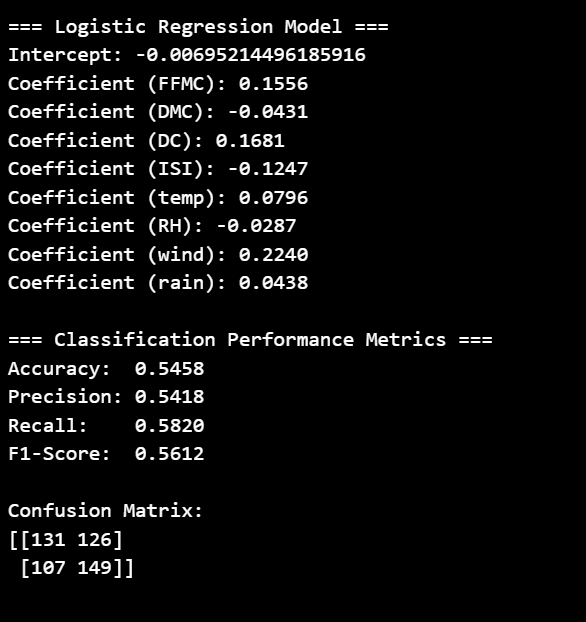


In [47]:
# STEP 8: CHECK ASSUMPTIONS
# 8.1 Variance Inflation Factor (VIF) for Multicollinearity
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import Ridge, Lasso, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    mean_squared_error
)

vif_data = pd.DataFrame()
vif_data["Feature"] = numerical_cols
vif_data["VIF"] = [
    variance_inflation_factor(X_cls_scaled, i) 
    for i in range(X_cls_scaled.shape[1])
]
print("\n=== Variance Inflation Factor (VIF) ===")
print(vif_data.to_string(index=False))


# -----------------------------------------------------------------------------
# STEP 9: SUMMARIZE FINDINGS
# -----------------------------------------------------------------------------
print("\n" + "="*50)
print("             STEP 9: SUMMARY OF FINDINGS           ")
print("="*50)



=== Variance Inflation Factor (VIF) ===
Feature      VIF
   FFMC 1.696803
    DMC 2.327714
     DC 2.077963
    ISI 1.578962
   temp 2.662988
     RH 1.897991
   wind 1.140405
   rain 1.044841

             STEP 9: SUMMARY OF FINDINGS           


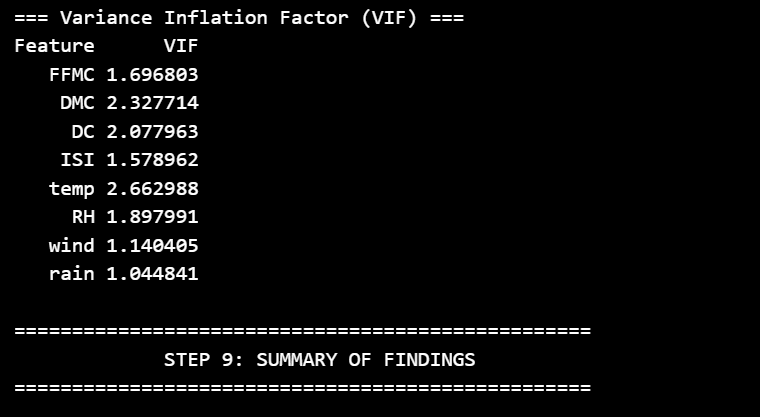
Interpretation of the Results
1. No Severe Multicollinearity Detected:
2. All VIF values range between 1.04 (rain) and 2.66 (temp).
3. Because every single value is well below the standard threshold of 5, there is no need to drop or combine any of these numerical features due to collinearity concerns.
4. Feature Breakdown:
5. temp (2.66) & DMC (2.33): Have the highest VIFs because temperature naturally correlates with moisture indices (like relative humidity and drought codes), but the level is low enough to safely keep both in the model.
6. wind (1.14) & rain (1.04): Have VIFs close to 1, meaning they move almost entirely independently of the other meteorological features.

In [ ]:
# STEP 9: SUMMARY OF FINDINGS
print("\n" + "="*50)
print("          STEP 9: SUMMARY OF FINDINGS          ")
print("="*50)

summary_text = """
1. DATA CLEANING & PREPROCESSING:
   - Initial dataset size: 517 rows.
   - Exact duplicates removed: 4 rows (cleaned size: 513 rows).
   - Target variable 'area' is heavily right-skewed; transformed to 'log_area' = log(area + 1).

2. ZERO INFLATION & DISTRIBUTION:
   - 247 out of 513 observations (48.1%) have area = 0.
   - Scatter plots and residual plots confirm severe zero-inflation, creating a structural bound (y = -fitted).

3. CORRELATION & FEATURE SELECTION:
   - Numerical predictors show very weak linear correlations with log_area (r <= 0.072).
   - Top 4 positive linear predictors: DC (r = 0.072), DMC (r = 0.072), wind (r = 0.068), temp (r = 0.055).

4. MODEL COMPARISON (OLS SPECIFICATIONS):
   - Categorical Model achieved highest raw R-squared (0.067), but was heavily penalized by BIC (1900.02).
   - Quadratic Model performed best overall on information criteria (AIC = 1794.84, BIC = 1824.52).
   - All OLS regression models explained < 3% of adjusted variance (Adj R-squared <= 0.027).

5. DIAGNOSTICS & MULTICOLLINEARITY (VIF):
   - All feature VIF values are between 1.04 and 2.66 (well below the threshold of 5.0).
   - Conclusion: No severe multicollinearity exists among the numerical predictors.

6. FINAL RECOMMENDATION:
   - Standard OLS regression performs poorly due to zero-inflation and non-linear dynamics.
   - Future modeling should utilize a Two-Stage / Hurdle Model (Classification for fire occurrence, followed by Regression for burned area).
"""

print(summary_text)


          STEP 9: SUMMARY OF FINDINGS          

1. DATA CLEANING & PREPROCESSING:
   - Initial dataset size: 517 rows.
   - Exact duplicates removed: 4 rows (cleaned size: 513 rows).
   - Target variable 'area' is heavily right-skewed; transformed to 'log_area' = log(area + 1).

2. ZERO INFLATION & DISTRIBUTION:
   - 247 out of 513 observations (48.1%) have area = 0.
   - Scatter plots and residual plots confirm severe zero-inflation, creating a structural bound (y = -fitted).

3. CORRELATION & FEATURE SELECTION:
   - Numerical predictors show very weak linear correlations with log_area (r <= 0.072).
   - Top 4 positive linear predictors: DC (r = 0.072), DMC (r = 0.072), wind (r = 0.068), temp (r = 0.055).

4. MODEL COMPARISON (OLS SPECIFICATIONS):
   - Categorical Model achieved highest raw R-squared (0.067), but was heavily penalized by BIC (1900.02).
   - Quadratic Model performed best overall on information criteria (AIC = 1794.84, BIC = 1824.52).
   - All OLS regression models e